# Readmission Analysis — Part 2: ML & Advanced Statistics

Predictive modeling and advanced validation for the complete cohort: Logistic Regression vs
Random Forest vs CatBoost, feature importance, SHAP, FAMD/UMAP, HDBSCAN clustering, decision-curve
analysis, calibration, bootstrap AUC comparison, fairness/equity, optimism-corrected validation,
the clinical risk-score tool, and the genuine PyHealth CCS coding supplement.

> Split from `Readmission_Full_Analysis.ipynb`. **Part 1
> (`Readmission_Descriptive_and_Inferential.ipynb`)** holds cohort description and classical
> inference. The preamble below re-runs the shared imports + feature engineering + modeling-matrix
> setup so this notebook is self-contained.


## Preamble — shared imports, feature engineering & modeling matrix
(identical to Part 1; re-run so Part 2 stands alone)

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score, confusion_matrix
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from catboost import CatBoostClassifier
import prince
import umap
import shap
import warnings
warnings.filterwarnings('ignore')

# ── Poster-quality global settings ──────────────────────────────────────────
plt.rcParams.update({
    'font.size': 14, 'axes.titlesize': 16, 'axes.labelsize': 14,
    'xtick.labelsize': 12, 'ytick.labelsize': 12, 'legend.fontsize': 12,
    'figure.dpi': 150, 'savefig.dpi': 300, 'savefig.bbox': 'tight',
    'font.family': 'DejaVu Sans',
})
BLUE, ORANGE = '#4C72B0', '#DD8452'
PALETTE = {'Not Readmitted': BLUE, 'Readmitted': ORANGE}
sns.set_style('whitegrid')

os.makedirs('figures', exist_ok=True)
print("✓ Libraries loaded. Figures will save to ./figures/")


/Users/matthewgold/.matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /var/folders/r7/sbbjx0ls4mqck4f3x1qfjkn00000gn/T/matplotlib-xyorr9p1 because there was an issue with the default path (/Users/matthewgold/.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Matplotlib is building the font cache; this may take a moment.


/Users/matthewgold/code/Readmission-analysis/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✓ Libraries loaded. Figures will save to ./figures/


In [2]:
# ── Load data ────────────────────────────────────────────────────────────────
df = pd.read_csv('data/annotated_psychiatric_data_complete.csv')

# ── Outcome ──────────────────────────────────────────────────────────────────
print("Readmissions value counts:")
print(df['Readmissions'].value_counts().sort_index())
df['readmitted'] = (df['Readmissions'].fillna(0) > 0).astype(int)

# ── Demographics ─────────────────────────────────────────────────────────────
df['age'] = pd.to_numeric(df['Pt_Age_Visit'], errors='coerce')
df['age_group'] = pd.cut(df['age'], bins=[5, 9, 11, 13, 19],
                          labels=['6–9', '10–11', '12–13', '14+'], right=True)
df['gender_male'] = (df['GenderCode'].str.strip().str.lower() == 'male').astype(int)
df['insurance_public'] = df['Insurance'].str.contains('AHCCCS', case=False, na=False).astype(int)

# ── ACE score ────────────────────────────────────────────────────────────────
df['ace_score'] = pd.to_numeric(df['ACEscore'], errors='coerce')
df['ace_high'] = (df['ace_score'] >= 4).astype(float)

# ── Restraints ───────────────────────────────────────────────────────────────
df['had_restraints'] = (pd.to_numeric(df['restraints'], errors='coerce').fillna(0) > 0).astype(int)

# ── C-SSRS flags ─────────────────────────────────────────────────────────────
# NOTE: The source CSV column is named 'Yellow flags (C-SRSS)' — a known typo in the
# raw export (letters transposed; should be C-SSRS). The column name must match the CSV
# exactly or yellow-flag coding silently returns all-zero on a refreshed export.
df['csrss_yellow'] = df['Yellow flags (C-SRSS)'].notna().astype(int)
df['csrss_orange'] = df['Orange flags (C-SSRS)'].notna().astype(int)
df['csrss_red']    = df['Red flags (C-SSRS)'].notna().astype(int)
df['csrss_any']    = ((df['csrss_yellow'] + df['csrss_orange'] + df['csrss_red']) > 0).astype(int)

# ── Length of stay (compute before date-quality filter) ──────────────────────
df['VisitDate'] = pd.to_datetime(df['VisitDate'], errors='coerce')
df['DischDate']  = pd.to_datetime(df['DischDate'],  errors='coerce')
df['los_days']   = (df['DischDate'] - df['VisitDate']).dt.days

# ── DATE QUALITY FILTER ───────────────────────────────────────────────────────
# Flag records with impossible or unusable dates and hold them out until reviewed.
flag_missing_visit  = df['VisitDate'].isna()
flag_missing_disch  = df['DischDate'].isna()
flag_negative_los   = df['los_days'].notna() & (df['los_days'] < 0)   # DischDate before VisitDate

flagged = df[flag_missing_visit | flag_missing_disch | flag_negative_los].copy()
flagged['flag_reason'] = ''
flagged.loc[flag_missing_visit[flagged.index], 'flag_reason'] += 'missing_VisitDate; '
flagged.loc[flag_missing_disch[flagged.index], 'flag_reason'] += 'missing_DischDate; '
flagged.loc[flag_negative_los[flagged.index], 'flag_reason']  += f'negative_LOS ({df.loc[flag_negative_los, "los_days"].min():.0f} to {df.loc[flag_negative_los, "los_days"].max():.0f} days); '

if len(flagged) > 0:
    flagged.to_csv('flagged_records_date_errors.csv', index=True)
    print(f"\n{'='*60}")
    print(f"  ⚠  DATE QUALITY FLAGS — {len(flagged)} records excluded")
    print(f"{'='*60}")
    print(f"  Missing VisitDate   : {flag_missing_visit.sum()}")
    print(f"  Missing DischDate   : {flag_missing_disch.sum()}")
    print(f"  Negative LOS        : {flag_negative_los.sum()} "
          f"(range: {df.loc[flag_negative_los,'los_days'].min():.0f} "
          f"to {df.loc[flag_negative_los,'los_days'].max():.0f} days)")
    print(f"\n  Readmission status of flagged records:")
    print(f"    Readmitted     : {flagged['readmitted'].sum()}")
    print(f"    Not readmitted : {(flagged['readmitted']==0).sum()}")
    print(f"\n  Saved for review → flagged_records_date_errors.csv")
    print(f"{'='*60}\n")
else:
    print("\n✓ No date-quality issues found.")

# Exclude flagged records from all downstream analysis
df = df[~(flag_missing_visit | flag_missing_disch | flag_negative_los)].copy()
df = df.reset_index(drop=True)

# ── Diagnostic complexity ─────────────────────────────────────────────────────
def count_csv(s):
    if pd.isna(s) or str(s).strip() == '': return 0
    return len([x for x in str(s).split(',') if x.strip()])

# NOTE: count_dsm5 is defined here for reference but is NOT used downstream.
# Unique cross-column DSM-5 category counts use unique_dsm5_count() instead,
# which deduplicates across VisitDiags and ChronicDiags columns.
def count_dsm5(s):  # unused — see unique_dsm5_count below
    if pd.isna(s) or str(s).strip() == '': return 0
    return len([x for x in str(s).split(';') if x.strip()])

df['n_visit_diags']   = df['VisitDiags'].apply(count_csv)
df['n_chronic_diags'] = df['ChronicDiags'].apply(count_csv)
df['n_total_diags']   = df['n_visit_diags'] + df['n_chronic_diags']

def unique_dsm5_count(row):
    cats = set()
    for col in ['VisitDiags_DSM5Categories', 'ChronicDiags_DSM5Categories']:
        val = row.get(col, '')
        if pd.notna(val) and str(val).strip():
            cats.update(c.strip() for c in str(val).split(';') if c.strip())
    return len(cats)

df['n_dsm5_categories'] = df.apply(unique_dsm5_count, axis=1)

# ── DSM-5 category flags (Original String Matching) ───────────────────────────
all_dsm5 = (df['VisitDiags_DSM5Categories'].fillna('') + ';' +
            df['ChronicDiags_DSM5Categories'].fillna('')).str.lower()

CATEGORY_FLAGS = {
    'has_nssi':        'non-suicidal self-injury',
    'has_trauma':      'trauma and stressor',
    'has_adhd':        'adhd',
    'has_asd':         'autism spectrum',
    'has_conduct':     'conduct disorder',
    'has_depression':  'depressive disorders',
    'has_anxiety':     'anxiety disorders',
    'has_bipolar':     'bipolar',
    'has_psychotic':   'psychotic',
    'has_intellectual':'intellectual disability',
    'has_ocd':         'obsessive-compulsive',
}
for flag, kw in CATEGORY_FLAGS.items():
    df[flag] = all_dsm5.str.contains(kw, na=False).astype(int)
# ── Medical comorbidity (Original Regex) ──────────────────────────────────────
def count_medical(s):
    if pd.isna(s) or str(s).strip() == '': return 0
    return sum(1 for c in str(s).split(',') if c.strip() and not c.strip().startswith('F'))

MEDICAL_COMORBIDITY_PATTERNS = {
    'Metabolic/Obesity': ('E66',),
    'Sleep Disorder': ('G47',),
    'GI/Digestive': ('K59', 'K21'),
    'Respiratory/Allergy': ('J30', 'R06'),
    'Renal/Urologic': ('N39',),
}

def get_medical_comorbidity_types(codes):
    if pd.isna(codes) or str(codes).strip() == '':
        return []
    code_tokens = [c.strip().upper() for c in str(codes).split(',') if c.strip()]
    return [
        category
        for category, prefixes in MEDICAL_COMORBIDITY_PATTERNS.items()
        if any(code.startswith(prefix) for code in code_tokens for prefix in prefixes)
    ]

df['n_medical_chronic']       = df['ChronicDiags'].apply(count_medical)
df['has_medical_comorbidity'] = (df['n_medical_chronic'] > 0).astype(int)
df['medical_comorbidity_types'] = df['ChronicDiags'].apply(get_medical_comorbidity_types)

# ── Medical comorbidity (Emulated CCS Mapping) ────────────────────────────────
def get_pyhealth_medical_comorbidity_types_emulated(codes):
    if pd.isna(codes) or str(codes).strip() == '':
        return []
    code_tokens = [c.strip().upper().replace('.', '') for c in str(codes).split(',') if c.strip()]
    types = []
    
    for c in code_tokens:
        if c.startswith(('E66', 'E4', 'E5', 'E6', 'E7', 'E8')):
            if 'Metabolic/Obesity_pyhealth' not in types: types.append('Metabolic/Obesity_pyhealth')
        if c.startswith(('G47',)):
            if 'Sleep Disorder_pyhealth' not in types: types.append('Sleep Disorder_pyhealth')
        if c.startswith(('K2', 'K3', 'K4', 'K5', 'K6', 'K7', 'K8', 'K9')):
            if 'GI/Digestive_pyhealth' not in types: types.append('GI/Digestive_pyhealth')
        if c.startswith(('J3', 'J4', 'R06', 'J8', 'J9')):
            if 'Respiratory/Allergy_pyhealth' not in types: types.append('Respiratory/Allergy_pyhealth')
        if c.startswith(('N3', 'N4', 'N1', 'N2')):
            if 'Renal/Urologic_pyhealth' not in types: types.append('Renal/Urologic_pyhealth')
    return types

df['medical_comorbidity_types_pyhealth'] = df['ChronicDiags'].apply(get_pyhealth_medical_comorbidity_types_emulated)
df['has_medical_comorbidity_pyhealth'] = (df['medical_comorbidity_types_pyhealth'].apply(len) > 0).astype(int)

# Count total non-mental health CCS categories roughly
df['n_medical_chronic_pyhealth'] = df['ChronicDiags'].apply(lambda x: sum(1 for c in str(x).split(',') if c.strip() and not c.strip().upper().startswith('F')))

print(f"✓ Feature engineering complete.")
print(f"  N = {len(df):,} (after date-quality exclusions) | "
      f"Readmitted = {df['readmitted'].sum():,} ({df['readmitted'].mean():.1%})")
print(f"  Age range: {df['age'].min():.0f}–{df['age'].max():.0f} yrs | "
      f"LOS: {df['los_days'].min():.0f}–{df['los_days'].max():.0f} days "
      f"(median {df['los_days'].median():.0f})")
print(f"  ACE score available: {df['ace_score'].notna().sum():,} "
      f"({df['ace_score'].notna().mean():.1%})")

# ── Batch-2 shared feature augmentation (suicidality-ICD, neurocognitive, distinct dx, ACE tiers, insurance, ICD chapters) ──
_allcodes = (df['VisitDiags'].fillna('')+','+df['NonSuicidialDiags'].fillna('')+','+df['ChronicDiags'].fillna('')).str.upper()
df['restraint_n'] = pd.to_numeric(df['restraints'], errors='coerce').fillna(0)
df['has_suicidal_ideation'] = _allcodes.str.contains('R45.851', regex=False).astype(int)
df['has_suicide_attempt']   = _allcodes.str.contains(r'T14\.91|Z91\.5', regex=True).astype(int)
_NEURO=['F02.80','F0280','F03.91','F0391','F05','F07.81','F0781','F09']
df['has_neurocognitive']=(all_dsm5.str.contains('neurocognitive',na=False)|_allcodes.apply(lambda s: any(c in s for c in _NEURO))).astype(int)
def _distinct_codes(r):
    s=set()
    for col in ['VisitDiags','NonSuicidialDiags','ChronicDiags']:
        v=r.get(col,'')
        if pd.notna(v) and str(v).strip(): s.update(t.strip().upper() for t in str(v).split(',') if t.strip())
    return len(s)
df['n_distinct_diagnoses']=df.apply(_distinct_codes,axis=1)
# physical ACE-Associated Health Conditions (ACEs Aware pediatric); psychiatric AAHCs excluded (circular in this cohort)
_PHYS_AAHC={'Asthma':('J45',),'Overweight/obesity':('E66','Z684'),'Allergy/atopy':('J30','T784'),
 'Eczema/dermatitis':('L20','L21','L23','L24','L25','L27','L28','L30'),'Urticaria':('L50',),
 'Headache/migraine':('R51','G43','G44'),'Somatic symptoms':('R10','R11','R42','K59'),
 'Sleep disturbance':('G47',),'Enuresis/encopresis':('N3944','R32','F980','R15','F981'),'Failure to thrive':('R6251','R627','R633')}
_norm=_allcodes.str.replace('.','',regex=False)
def _has_pref(prefixes):
    return pd.Series([any(any(t.startswith(p) for t in s.split(',')) for p in prefixes) for s in _norm], index=df.index)
_ace_cond=pd.DataFrame({k:_has_pref(v) for k,v in _PHYS_AAHC.items()})
df['has_ace_condition']=(_ace_cond.sum(axis=1)>0).astype(int)
def _ace_tier(a,c):
    if pd.isna(a): return np.nan
    if a==0: return 'Low'
    if a>=4: return 'High'
    return 'High' if c==1 else 'Intermediate'
df['ace_risk_tier']=[_ace_tier(a,c) for a,c in zip(df['ace_score'],df['has_ace_condition'])]
df['high_ace_expanded']=df['ace_risk_tier'].map({'Low':0,'Intermediate':0,'High':1})
# richer insurance categories: Public / Commercial / Military / Tribal-IHS / Other
def _ins_cat(x):
    s=str(x).upper()
    if any(k in s for k in ['AHCCCS','MEDICAID','MAGELLAN','HCIC','AFMC','CREWS']): return 'Public'
    if any(k in s for k in ['TRICARE','CHAMPVA']): return 'Military'
    if any(k in s for k in ['GILA RIVER','NAVAJO','INDIAN HEALTH','IHS']): return 'Tribal/IHS'
    if pd.isna(x) or s in ('NAN','','OUT OF NETWORK','SP SPECIAL ARRANGEMENT','CHARITY CARE'): return 'Other/unknown'
    return 'Commercial'
df['insurance_cat5']=df['Insurance'].apply(_ins_cat)
# ICD-10 chapter set per patient (first-letter based)
_ICD_CH={'A':'Infectious','B':'Infectious','C':'Neoplasm','D':'Blood/neoplasm','E':'Endocrine/metabolic','F':'Mental/behavioral',
 'G':'Nervous','H':'Eye/ear','I':'Circulatory','J':'Respiratory','K':'Digestive','L':'Skin','M':'Musculoskeletal',
 'N':'Genitourinary','P':'Perinatal','Q':'Congenital','R':'Symptoms/signs','S':'Injury','T':'Injury/poisoning','Z':'Status/Z-codes'}
def _chapters(r):
    s=set()
    for col in ['VisitDiags','NonSuicidialDiags','ChronicDiags']:
        v=r.get(col,'')
        if pd.notna(v) and str(v).strip():
            for t in str(v).split(','):
                t=t.strip().upper()
                if t: s.add(_ICD_CH.get(t[0],'Other'))
    return s
df['_icd_chapters']=df.apply(_chapters,axis=1)
print(f"  +Batch-2 features: suicidal_ideation={int(df.has_suicidal_ideation.sum())}, neurocognitive={int(df.has_neurocognitive.sum())}, "
      f"distinct_dx median={df.n_distinct_diagnoses.median():.0f}, high_ACE(expanded)={int(df.high_ace_expanded.fillna(0).sum())}; "
      f"insurance5={dict(df.insurance_cat5.value_counts())}")


Readmissions value counts:
Readmissions
0    2406
1     219
2      25
3       2
Name: count, dtype: int64

✓ No date-quality issues found.
✓ Feature engineering complete.
  N = 2,652 (after date-quality exclusions) | Readmitted = 246 (9.3%)
  Age range: 5–12 yrs | LOS: 1–112 days (median 8)
  ACE score available: 1,569 (59.2%)


  +Batch-2 features: suicidal_ideation=1346, neurocognitive=8, distinct_dx median=6, high_ACE(expanded)=996; insurance5={'Public': np.int64(1631), 'Commercial': np.int64(896), 'Military': np.int64(65), 'Other/unknown': np.int64(45), 'Tribal/IHS': np.int64(15)}

In [3]:
# ── Logistic regression: build feature matrix ─────────────────────────────────

FEATURES = {
    # Demographics
    'age':                   'Age at admission (yrs)',
    'gender_male':           'Male gender identity (recorded at admission)',  # GenderCode = gender ID, NOT sex
    'insurance_public':      'Public insurance (AHCCCS)',
    # Clinical
    'ace_score':             'ACE score',
    'had_restraints':        'Physical restraint use',
    'csrss_any':             'Any C-SSRS flag (suicidality screen)',
    'los_days':              'Length of stay (days)',
    # Diagnostic complexity (distinct DSM-5 *categories*, not # of diagnoses)
    'n_dsm5_categories':     '# distinct DSM-5 categories',
    'has_medical_comorbidity': 'Medical comorbidity (ICD-prefix group flag; not a CCS category)',
    # Diagnosis flags = string match on DSM-5 *category* labels (NOT individual ICD codes, NOT PyHealth CCSR)
    'has_nssi':              'Non-suicidal self-injury (DSM-5 category)',
    'has_trauma':            'Trauma/stressor disorders (DSM-5 category)',
    'has_adhd':              'ADHD (DSM-5 category)',
    'has_asd':               'Autism spectrum (DSM-5 category)',
    'has_conduct':           'Conduct disorder (DSM-5 category)',
    'has_depression':        'Depressive disorders (DSM-5 category)',
    'has_anxiety':           'Anxiety disorders (DSM-5 category)',
    'has_bipolar':           'Bipolar disorders (DSM-5 category)',
    'has_psychotic':         'Psychotic disorders (DSM-5 category)',
    # Batch-2 additions (suicidality by ICD code; organic/neurocognitive flag)
    'has_suicidal_ideation': 'Suicidal ideation (ICD R45.851)',
    'has_neurocognitive':    'Neurocognitive/organic (ICD)',
}

feat_cols = list(FEATURES.keys())
model_df  = df[feat_cols + ['readmitted', 'csrss_red', 'csrss_orange', 'csrss_yellow', 'n_medical_chronic_pyhealth', 'has_ace_condition', 'high_ace_expanded']].copy()

# MICE Imputation for missing ACE Score and LOS
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.ensemble import RandomForestRegressor

imp_cols = ['age', 'ace_score', 'los_days']
imputer = IterativeImputer(estimator=RandomForestRegressor(n_estimators=50, random_state=42), max_iter=10, random_state=42)

model_df[imp_cols] = imputer.fit_transform(model_df[imp_cols])

# Handle any remaining missing values
model_df = model_df.dropna()

print(f"Model dataset: {len(model_df):,} patients | {model_df['readmitted'].sum()} readmitted ({model_df['readmitted'].mean():.1%})")
print(f"Features: {len(feat_cols)}")

Model dataset: 1,569 patients | 140 readmitted (8.9%)
Features: 20


In [4]:
# ── Logistic regression model + interaction terms ─────────────────────────────
# We test specific interactions hypothesized to be clinically relevant

# Keep a copy of unscaled for tree models
model_df_unscaled = model_df.copy()

# Standardize continuous variables for Odds Ratio interpretation and visible CIs
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scale_cols = ['age', 'los_days', 'ace_score', 'n_dsm5_categories']
model_df[scale_cols] = scaler.fit_transform(model_df[scale_cols])

interaction_labels = {
    'complexity_x_age': 'Age × Diagnostic Complexity',
    'ace_x_csrss':      'ACE Score × Any C-SSRS Flag',
    'medical_x_los':    'Medical Comorbidity × LOS',
}

model_df['complexity_x_age'] = model_df['n_dsm5_categories'] * model_df['age']
model_df['ace_x_csrss']      = model_df['ace_score'] * model_df['csrss_any']
model_df['medical_x_los']    = model_df['has_medical_comorbidity'] * model_df['los_days']
model_df_unscaled['complexity_x_age'] = model_df_unscaled['n_dsm5_categories'] * model_df_unscaled['age']
model_df_unscaled['ace_x_csrss']      = model_df_unscaled['ace_score'] * model_df_unscaled['csrss_any']
model_df_unscaled['medical_x_los']    = model_df_unscaled['has_medical_comorbidity'] * model_df_unscaled['los_days']

all_x_cols = feat_cols + list(interaction_labels.keys())

# Scale interactions
scaler_interactions = StandardScaler()
model_df[list(interaction_labels.keys())] = scaler_interactions.fit_transform(model_df[list(interaction_labels.keys())])


X = model_df[all_x_cols]
X = sm.add_constant(X)
y = model_df['readmitted']

logit_model = sm.Logit(y, X).fit(maxiter=200, disp=0)
all_labels = {**FEATURES, **interaction_labels}   # needed by downstream ML cells
print('(Logistic regression results + forest plot live in Part 1; the model is refit here\n silently only to supply the modeling matrix X/y and labels to the ML cells below.)')

(Logistic regression results + forest plot live in Part 1; the model is refit here
 silently only to supply the modeling matrix X/y and labels to the ML cells below.)


In [5]:
# Restore a derived column defined in a Part-1 descriptive cell that downstream cells reference
df['complexity_q'] = pd.qcut(df['n_dsm5_categories'], q=4,
                              labels=['Q1 (1 cat.)', 'Q2 (2)', 'Q3 (3)', 'Q4 (4+)'],
                              duplicates='drop')


In [6]:
# ── ML: prepare feature matrix (same features + interactions) ─────────────────
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

ml_cols = all_x_cols   # same features as logistic regression (incl. interactions)
X_ml = model_df[ml_cols].values
X_ml_raw = model_df_unscaled[ml_cols].values

y_ml = model_df['readmitted'].values

print(f"Machine Learning feature matrix shape: {X_ml.shape}")

# Stratified 10-Fold Cross-Validation
# (10-fold matches the optimism-correction pipeline in Readmission_PyHealth_Advanced.ipynb
#  and the Methods section of the AACAP 2026 abstract.)
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
feature_labels = [all_labels.get(c, c) for c in ml_cols]


Machine Learning feature matrix shape: (1569, 23)


In [7]:
# ── ML model training and evaluation function ─────────────────────────────────

def evaluate_model(model, name, X, y, cv, use_smote=False):
    if use_smote:
        # Create pipeline with SMOTE
        pipeline = ImbPipeline([
            ('smote', SMOTE(random_state=42)),
            ('classifier', model)
        ])
    else:
        pipeline = model
        
    probs = np.zeros(len(y))
    for train_idx, test_idx in cv.split(X, y):
        # We need to drop NA from the specific fold if there are still any missing (though MICE should have handled it)
        # Assuming MICE worked and there are no NaNs in X
        
        # Fit on training fold
        pipeline.fit(X[train_idx], y[train_idx])
        
        # Predict on test fold
        if hasattr(pipeline, "predict_proba"):
            probs[test_idx] = pipeline.predict_proba(X[test_idx])[:, 1]
        else:
            # For models like logistic regression statsmodels, we handle it separately
            pass
            
    auc = roc_auc_score(y, probs)
    ap = average_precision_score(y, probs)
    print(f"{name:20s} — AUC: {auc:.3f}  |  AP: {ap:.3f}")
    return probs, auc, ap

# ── Logistic Regression ───────────────────────────────────────────────────────
lr_probs = np.zeros(len(y_ml))
for train_idx, test_idx in cv.split(X_ml, y_ml):
    # Statsmodels doesn't easily work with imblearn pipeline without a wrapper, 
    # so we'll evaluate it here without SMOTE first, or write a quick wrapper.
    # We will just evaluate it directly.
    X_tr = sm.add_constant(X_ml[train_idx], has_constant='add')
    X_te = sm.add_constant(X_ml[test_idx],  has_constant='add')
    m = sm.Logit(y_ml[train_idx], X_tr).fit(disp=0, maxiter=200)
    lr_probs[test_idx] = m.predict(X_te)

lr_auc = roc_auc_score(y_ml, lr_probs)
lr_ap  = average_precision_score(y_ml, lr_probs)
print(f"{'Logistic Regr':20s} — AUC: {lr_auc:.3f}  |  AP: {lr_ap:.3f}")

# ── Random Forest ─────────────────────────────────────────────────────────────
rf = RandomForestClassifier(
    n_estimators=500, max_depth=6, min_samples_leaf=10,
    class_weight='balanced', random_state=42, n_jobs=-1
)
rf_probs, rf_auc, rf_ap = evaluate_model(rf, "Random Forest", X_ml, y_ml, cv, use_smote=False)

# ── Random Forest (with SMOTE inside CV) ──────────────────────────────────────
rf_smote = RandomForestClassifier(
    n_estimators=500, max_depth=6, min_samples_leaf=10,
    random_state=42, n_jobs=-1
)
rf_smote_probs, rf_smote_auc, rf_smote_ap = evaluate_model(rf_smote, "Random Forest (SMOTE)", X_ml, y_ml, cv, use_smote=True)


# ── CatBoost (Numerical encoded) ──────────────────────────────────────────────
cat_num = CatBoostClassifier(
    iterations=500, depth=4, learning_rate=0.05,
    auto_class_weights='Balanced', eval_metric='AUC',
    random_seed=42, verbose=0,
)
cat_probs, cat_auc, cat_ap = evaluate_model(cat_num, "CatBoost", X_ml, y_ml, cv, use_smote=False)

# ── CatBoost (Native Categoricals) ────────────────────────────────────────────
# Rebuild the dataset for CatBoost native categorical handling
native_cat_cols = ['gender_male', 'insurance_public', 'had_restraints', 'csrss_any', 'has_medical_comorbidity']
native_cat_cols += [c for c in FEATURES.keys() if c.startswith('has_') and c != 'has_medical_comorbidity']

cat_features_indices = [model_df[feat_cols].columns.get_loc(c) for c in native_cat_cols if c in model_df[feat_cols].columns]
# We must convert to object/string so CatBoost knows it's categorical, float array fails
X_ml_cat_df = model_df_unscaled[feat_cols].copy()
for col in native_cat_cols:
    X_ml_cat_df[col] = X_ml_cat_df[col].astype(str)
X_ml_cat = X_ml_cat_df.values # Original unencoded categorical base features

cat_native = CatBoostClassifier(
    iterations=500, depth=4, learning_rate=0.05,
    auto_class_weights='Balanced', eval_metric='AUC',
    random_seed=42, verbose=0,
    cat_features=cat_features_indices
)

cat_native_probs, cat_native_auc, cat_native_ap = evaluate_model(cat_native, "CatBoost (Native Cat)", X_ml_cat, y_ml, cv, use_smote=False)

Logistic Regr        — AUC: 0.680  |  AP: 0.159


Random Forest        — AUC: 0.659  |  AP: 0.155


  File "/Users/matthewgold/code/Readmission-analysis/.venv/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py", line 249, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_darwin()
                         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthewgold/code/Readmission-analysis/.venv/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py", line 318, in _count_physical_cores_darwin
    return int(cpu_info)
           ^^^^^^^^^^^^^


Random Forest (SMOTE) — AUC: 0.657  |  AP: 0.144


CatBoost             — AUC: 0.593  |  AP: 0.121


CatBoost (Native Cat) — AUC: 0.612  |  AP: 0.132


## Supplement — Genuine PyHealth CCS coding (ICD-10-CM → CCSCM)

The primary regression uses the curated regex DSM-5 category flags. As a standardized-coding
robustness check, this section maps the cohort's raw ICD-10-CM codes to **CCS** categories using
the genuine `pyhealth.medcode.CrossMap` (with a local description fallback), then compares the
hand-built DSM-5 flags against the standardized CCS encoding. Ported from
`Readmission_PyHealth_Advanced.ipynb` (B1–B4). The whole section self-skips if PyHealth is
unavailable, so the rest of the notebook is unaffected.

In [8]:
# ── B1: Collect cohort ICD-10 codes & validate against PyHealth ICD-10-CM ──────
DIAG_COLS = ['VisitDiags', 'ChronicDiags', 'NonSuicidialDiags']

def parse_codes(s):
    """Split a comma-separated ICD code cell into cleaned tokens."""
    if pd.isna(s) or str(s).strip() == '':
        return []
    return [c.strip().upper() for c in str(s).split(',') if c.strip()]

# Per-patient code sets (union across the diagnosis columns; .get guards missing cols)
patient_codes = df.apply(lambda r: sorted({c for col in DIAG_COLS for c in parse_codes(r.get(col))}), axis=1)
all_codes = sorted({c for codes in patient_codes for c in codes})
print(f"Distinct ICD-10 codes in cohort: {len(all_codes):,}")

# ── Load PyHealth ICD-10-CM InnerMap (with local fallback) ────────────────────
USE_PYHEALTH = True
icd = None
try:
    from pyhealth.medcode import InnerMap, CrossMap
    icd = InnerMap.load('ICD10CM')
    print('✓ PyHealth ICD10CM InnerMap loaded.')
except Exception as e:
    USE_PYHEALTH = False
    print(f'⚠ PyHealth unavailable ({e}); falling back to local reference files.')

local_desc = {}
try:
    with open('icd_descriptions_full.json') as fh:
        local_desc = {k.strip().upper(): v for k, v in json.load(fh).items()}
except Exception:
    pass

def pyhealth_lookup(code):
    if icd is None:
        return (code in local_desc, local_desc.get(code, ''))
    variants = [code, code.replace('.', '')]
    if '.' not in code and len(code) > 3:
        variants.append(code[:3] + '.' + code[3:])
    for v in variants:
        try:
            return True, icd.lookup(v)
        except Exception:
            continue
    return False, ''

valid_flags, descriptions = {}, {}
for c in all_codes:
    ok, desc = pyhealth_lookup(c)
    valid_flags[c] = ok
    descriptions[c] = desc

n_valid = sum(valid_flags.values())
print(f"Valid ICD-10-CM codes: {n_valid:,}/{len(all_codes):,} "
      f"({n_valid/max(len(all_codes),1):.1%})")

recon = pd.DataFrame({
    'icd_code': all_codes,
    'valid_icd10cm': [valid_flags[c] for c in all_codes],
    'pyhealth_description': [descriptions[c] for c in all_codes],
})
recon['n_patients'] = [int(sum(c in s for s in patient_codes)) for c in all_codes]
recon = recon.sort_values('n_patients', ascending=False).reset_index(drop=True)
recon.to_csv('figures/PyHealth_ICD_validation.csv', index=False)
print('✓ Saved reconciliation table → figures/PyHealth_ICD_validation.csv')

Distinct ICD-10 codes in cohort: 1,863


✓ PyHealth ICD10CM InnerMap loaded.
Valid ICD-10-CM codes: 1,843/1,863 (98.9%)


✓ Saved reconciliation table → figures/PyHealth_ICD_validation.csv


In [9]:
# ── B2: Map ICD-10 codes to standardized CCS categories (PyHealth CrossMap) ────
ccs_map, ccs_labels = None, None
if USE_PYHEALTH:
    try:
        ccs_map = CrossMap.load('ICD10CM', 'CCSCM')
        ccs_labels = InnerMap.load('CCSCM')
        print('✓ PyHealth CrossMap ICD10CM→CCSCM and CCSCM labels loaded.')
    except Exception as e:
        print(f'⚠ CCS mapping unavailable ({e}); CCS features will be skipped.')

def code_to_ccs(code):
    if ccs_map is None:
        return (None, None)
    variants = [code, code.replace('.', '')]
    if '.' not in code and len(code) > 3:
        variants.append(code[:3] + '.' + code[3:])
    for v in variants:
        try:
            mapped = ccs_map.map(v)
        except Exception:
            mapped = []
        if mapped:
            cc = mapped[0]
            try:
                lab = ccs_labels.lookup(cc)
            except Exception:
                lab = cc
            return (cc, lab)
    return (None, None)

code2ccs = {c: code_to_ccs(c) for c in all_codes}

# ── Part B: decompose CCS 653 "Residual codes; unclassified" into clinically meaningful groups ──
# PyHealth's ICD10CM→CCSCM CrossMap routes a HETEROGENEOUS set of codes to the catch-all
# "Residual codes; unclassified" — not just organic/neurocognitive F-codes, but sleep-wake (G47),
# symptom (R-) and status/psychosocial (Z-) codes. Treating that bucket as a single comorbidity is
# misleading, so we relabel by code family (genuinely ambiguous codes stay residual). Only codes
# currently in the residual bucket are touched; validly-mapped codes are left untouched.
def _reclass_residual(code, label):
    if label is None or 'residual' not in str(label).lower():
        return None                       # only decompose the residual bucket
    c = code.replace('.', '').upper()
    if c.startswith(('F02','F03','F05','F07','F09')) or c in ('R413','R4182','R404'):
        return ('NEURO_DX', 'Neurocognitive Disorders')        # dementia/delirium/organic + cognitive symptoms
    if c.startswith('G47'):
        return ('SLEEP_DX', 'Sleep-Wake Disorders')
    if c.startswith('Z'):
        return ('ZSTATUS', 'Status/psychosocial (Z-codes)')
    return None                            # leave true residual (e.g. nonspecific R-codes) as-is
_recl = {}
for _c in list(code2ccs.keys()):
    _new = _reclass_residual(_c, code2ccs.get(_c, (None, None))[1])
    if _new is not None:
        code2ccs[_c] = _new
        _recl.setdefault(_new[1], []).append(_c)
print("Part B: decomposed 'Residual codes; unclassified' →")
for _k, _v in _recl.items():
    print(f"   {_k}: {len(_v)} codes  e.g. {sorted(_v)[:6]}")
_still = [c for c,(cc,lab) in code2ccs.items() if lab and 'residual' in str(lab).lower()]
# Eliminate the catch-all entirely: relabel any code still in "Residual codes; unclassified" by family
for _c in list(code2ccs.keys()):
    _cc,_lab=code2ccs.get(_c,(None,None))
    if _lab and 'residual' in str(_lab).lower():
        _n=_c.replace('.','').upper()
        code2ccs[_c]=('OTHER_SX','Other symptoms/signs') if _n.startswith('R') else ('OTHER_UNCL','Other/unclassified (non-specific)')
print(f"   relabeled remaining {len(_still)} code(s) out of 'Residual codes; unclassified' -> Other symptoms/signs or Other")

n_ccs_mapped = sum(1 for v in code2ccs.values() if v[0] is not None)
print(f"Codes mapped to a CCS category: {n_ccs_mapped:,}/{len(all_codes):,} "
      f"({n_ccs_mapped/max(len(all_codes),1):.1%})")

ccs_patient_counts = {}
for codes in patient_codes:
    cats = {code2ccs[c][1] for c in codes if code2ccs.get(c, (None, None))[0] is not None}
    for cat in cats:
        ccs_patient_counts[cat] = ccs_patient_counts.get(cat, 0) + 1

ccs_prev = (pd.Series(ccs_patient_counts).sort_values(ascending=False)
            .rename('n_patients').to_frame()) if ccs_patient_counts else pd.DataFrame()
if len(ccs_prev):
    ccs_prev['pct_patients'] = (ccs_prev['n_patients'] / len(df) * 100).round(1)
    print(f"\nDistinct CCS categories present in cohort: {len(ccs_prev)}")
    print('\nTop 15 CCS categories by patient prevalence:')
    print(ccs_prev.head(15).to_string())
else:
    print('No CCS categories mapped — supplement will report unavailable below.')

✓ PyHealth CrossMap ICD10CM→CCSCM and CCSCM labels loaded.
Part B: decomposed 'Residual codes; unclassified' →
   Sleep-Wake Disorders: 15 codes  e.g. ['G47.00', 'G47.01', 'G47.10', 'G47.11', 'G47.19', 'G47.30']
   Neurocognitive Disorders: 3 codes  e.g. ['R40.4', 'R41.3', 'R41.82']
   Status/psychosocial (Z-codes): 51 codes  e.g. ['Z14.1', 'Z14.8', 'Z15.89', 'Z28.82', 'Z72.0', 'Z72.4']
   relabeled remaining 13 code(s) out of 'Residual codes; unclassified' -> Other symptoms/signs or Other
Codes mapped to a CCS category: 1,719/1,863 (92.3%)

Distinct CCS categories present in cohort: 177

Top 15 CCS categories by patient prevalence:
                                                       n_patients  pct_patients
Mood disorders                                               1827          68.9
Anxiety disorders                                            1700          64.1
"Attention-deficit                                           1637          61.7
Suicide and intentional self-inflicted 

In [10]:
# ── B3: Build patient-level CCS comorbidity features ──────────────────────────
ccs_features, ccs_feature_cols, top_ccs = None, [], []
if len(ccs_prev):
    TOP_K_CCS = 15
    top_ccs = list(ccs_prev.head(TOP_K_CCS).index)
    patient_ccs_sets = [
        {code2ccs[c][1] for c in codes if code2ccs.get(c, (None, None))[0] is not None}
        for codes in patient_codes
    ]
    ccs_features = pd.DataFrame(index=df.index)
    ccs_features['readmitted'] = df['readmitted'].values
    ccs_features['n_ccs_categories'] = [len(s) for s in patient_ccs_sets]

    def ccs_colname(label):
        slug = ''.join(ch if ch.isalnum() else '_' for ch in str(label).lower())
        return 'ccs__' + slug[:40].strip('_')

    for cat in top_ccs:
        col = ccs_colname(cat)
        ccs_features[col] = [1 if cat in s else 0 for s in patient_ccs_sets]
        ccs_feature_cols.append(col)

    ccs_features.to_csv('figures/PyHealth_CCS_patient_features.csv', index=False)
    print(f"Built {len(ccs_feature_cols)} CCS indicator features + n_ccs_categories.")
    print(f"Patients with >=1 mapped CCS category: "
          f"{(ccs_features['n_ccs_categories'] > 0).mean():.1%}")
    print('✓ Saved → figures/PyHealth_CCS_patient_features.csv')
else:
    print('⚠ CCS features skipped (no mapping available).')

Built 15 CCS indicator features + n_ccs_categories.
Patients with >=1 mapped CCS category: 100.0%
✓ Saved → figures/PyHealth_CCS_patient_features.csv


Univariate readmission association by CCS category (Haldane-corrected ORs):
                                         CCS category  N exposed    OR  OR_lo  OR_hi     p
               Disorders usually diagnosed in infancy        843 2.137  1.641  2.784 0.000
                                       Mood disorders       1827 1.953  1.410  2.704 0.000
                              Developmental disorders        295 1.944  1.374  2.751 0.000
                            Impulse control disorders        293 1.900  1.339  2.697 0.000
                                    Anxiety disorders       1700 1.860  1.374  2.519 0.000
                                    Attention-deficit       1637 1.850  1.377  2.485 0.000
                         Blindness and vision defects        216 1.606  1.063  2.425 0.024
        Suicide and intentional self-inflicted injury       1428 1.513  1.154  1.982 0.003
                        Status/psychosocial (Z-codes)        288 1.480  1.017  2.152 0.041
              

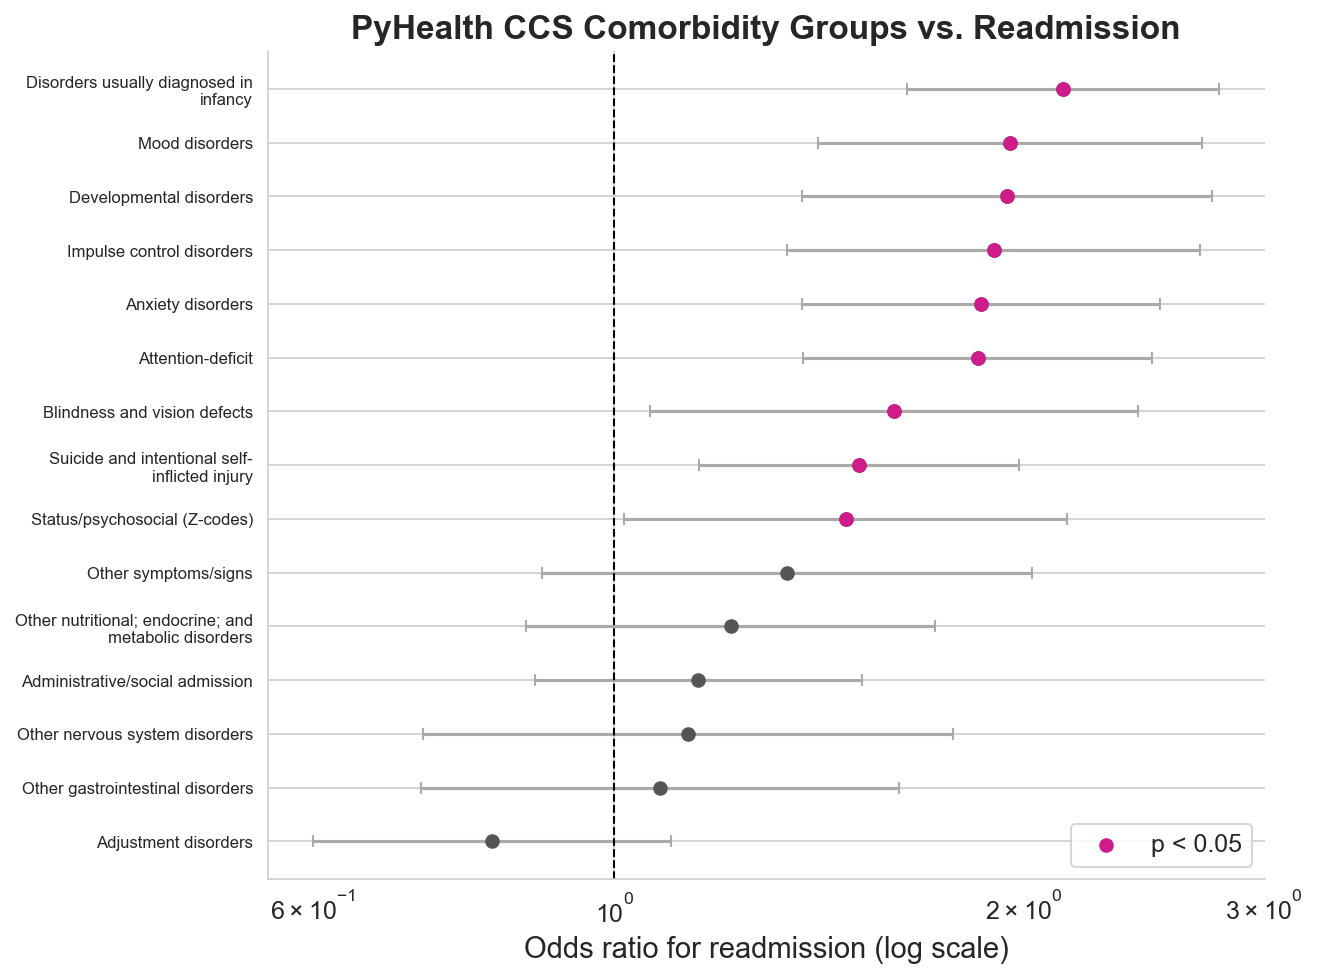


Incremental predictive value (OOF logistic AUC):
  Base (demographic + clinical)      AUC = 0.548
  Base + regex DSM-5 flags           AUC = 0.660


  Base + PyHealth CCS features       AUC = 0.693
  Base + DSM-5 + CCS                 AUC = 0.697
✓ Saved → figures/PyHealth_CCS_forest.png, figures/PyHealth_CCS_associations.csv


In [11]:
# ── B4: CCS readmission associations + comparison vs regex DSM-5 flags ────────
if ccs_features is not None and len(ccs_feature_cols):
    from statsmodels.stats.contingency_tables import Table2x2
    from sklearn.linear_model import LogisticRegression
    from sklearn.model_selection import cross_val_predict

    y_b = ccs_features['readmitted'].values

    rows = []
    for cat, col in zip(top_ccs, ccs_feature_cols):
        x = ccs_features[col].values
        a = int(((x == 1) & (y_b == 1)).sum()); b = int(((x == 1) & (y_b == 0)).sum())
        c = int(((x == 0) & (y_b == 1)).sum()); d = int(((x == 0) & (y_b == 0)).sum())
        tbl = Table2x2(np.array([[a + 0.5, b + 0.5], [c + 0.5, d + 0.5]]))  # Haldane
        rows.append({'CCS category': str(cat).strip('\'"').strip(), 'N exposed': a + b,
                     'OR': tbl.oddsratio, 'OR_lo': tbl.oddsratio_confint()[0],
                     'OR_hi': tbl.oddsratio_confint()[1], 'p': tbl.oddsratio_pvalue()})
    ccs_assoc = pd.DataFrame(rows).sort_values('OR', ascending=False).reset_index(drop=True)
    ccs_assoc.to_csv('figures/PyHealth_CCS_associations.csv', index=False)
    print('Univariate readmission association by CCS category (Haldane-corrected ORs):')
    print(ccs_assoc.round(3).to_string(index=False))

    fig, ax = plt.subplots(figsize=(9, max(4, 0.45 * len(ccs_assoc))))
    ypos = np.arange(len(ccs_assoc))[::-1]
    sig = ccs_assoc['p'] < 0.05
    ax.errorbar(ccs_assoc['OR'], ypos,
                xerr=[ccs_assoc['OR'] - ccs_assoc['OR_lo'], ccs_assoc['OR_hi'] - ccs_assoc['OR']],
                fmt='o', color='#555', ecolor='#aaa', capsize=3, zorder=2)
    ax.scatter(ccs_assoc.loc[sig, 'OR'], ypos[sig.values], color='#d01c8b', zorder=3, label='p < 0.05')
    ax.axvline(1.0, color='k', ls='--', lw=1)
    ax.set_yticks(ypos); ax.set_yticklabels([__import__('textwrap').fill(str(_l), 34) for _l in ccs_assoc['CCS category']], fontsize=8)  # noqa: E702
    ax.set_xscale('log'); ax.set_xlabel('Odds ratio for readmission (log scale)')  # noqa: E702
    ax.set_title('PyHealth CCS Comorbidity Groups vs. Readmission', fontweight='bold')
    ax.legend(loc='lower right')
    for sp in ('top', 'right'):
        ax.spines[sp].set_visible(False)
    plt.tight_layout(); plt.savefig('figures/PyHealth_CCS_forest.png'); plt.show()  # noqa: E702

    # Incremental value: regex DSM-5 flags vs standardized CCS encoding (OOF logistic AUC)
    base_cols = ['age', 'gender_male', 'insurance_public', 'ace_score', 'had_restraints',
                 'csrss_any', 'los_days']
    dsm5_cols = list(CATEGORY_FLAGS)
    base_df = df.copy()
    base_df['ace_score'] = base_df['ace_score'].fillna(base_df['ace_score'].median())
    base_df['los_days']  = base_df['los_days'].fillna(base_df['los_days'].median())

    def oof_auc(frame):
        Xv = frame.values.astype(float)
        lr = LogisticRegression(max_iter=2000, class_weight='balanced')
        p = cross_val_predict(lr, Xv, y_b, cv=cv, method='predict_proba')[:, 1]
        return roc_auc_score(y_b, p)

    feature_sets = {
        'Base (demographic + clinical)': base_df[base_cols],
        'Base + regex DSM-5 flags':      pd.concat([base_df[base_cols], base_df[dsm5_cols]], axis=1),
        'Base + PyHealth CCS features':  pd.concat([base_df[base_cols].reset_index(drop=True),
                                                    ccs_features[['n_ccs_categories'] + ccs_feature_cols]], axis=1),
        'Base + DSM-5 + CCS':            pd.concat([base_df[base_cols].reset_index(drop=True),
                                                    base_df[dsm5_cols].reset_index(drop=True),
                                                    ccs_features[['n_ccs_categories'] + ccs_feature_cols]], axis=1),
    }
    print('\nIncremental predictive value (OOF logistic AUC):')
    for name, frame in feature_sets.items():
        print(f"  {name:<34} AUC = {oof_auc(frame):.3f}")
    print('✓ Saved → figures/PyHealth_CCS_forest.png, figures/PyHealth_CCS_associations.csv')
else:
    print('⚠ CCS association analysis skipped (no CCS features available).')

## Supplement — Advanced statistical validation

Ported from `Readmission_PyHealth_Advanced.ipynb` (C1–C4): bootstrap confidence intervals for
discrimination, calibration metrics with Platt/isotonic recalibration, formal fairness/equity
metrics, and optimism-corrected validation. All operate on the cross-validated out-of-fold model
predictions already computed above (`lr_probs`, `rf_probs`, `cat_probs`).

In [12]:
# ── Advanced-stats setup: registry of OOF predictions + shared constants ─────
from sklearn.metrics import brier_score_loss, average_precision_score
from sklearn.calibration import calibration_curve

RNG_SEED = 42
MODELS = {'Logistic Regression': lr_probs, 'Random Forest': rf_probs, 'CatBoost': cat_probs}
MODEL_COLORS = {'Logistic Regression': '#2166ac', 'Random Forest': '#4dac26', 'CatBoost': '#d01c8b'}
print("Advanced-stats registry ready:", ", ".join(MODELS))
for name, p in MODELS.items():
    print(f"  {name:<22} AUC={roc_auc_score(y_ml, p):.3f}  AP={average_precision_score(y_ml, p):.3f}")

Advanced-stats registry ready: Logistic Regression, Random Forest, CatBoost
  Logistic Regression    AUC=0.680  AP=0.159
  Random Forest          AUC=0.659  AP=0.155
  CatBoost               AUC=0.593  AP=0.121


Bootstrap 95% CIs (B=2,000, stratified):
                     AUC-ROC  ROC 2.5%  ROC 97.5%  AUC-PR  PR 2.5%  PR 97.5%
Model                                                                       
Logistic Regression    0.680     0.635      0.722   0.159    0.134     0.203
Random Forest          0.659     0.617      0.702   0.155    0.128     0.206
CatBoost               0.593     0.545      0.643   0.121    0.103     0.151


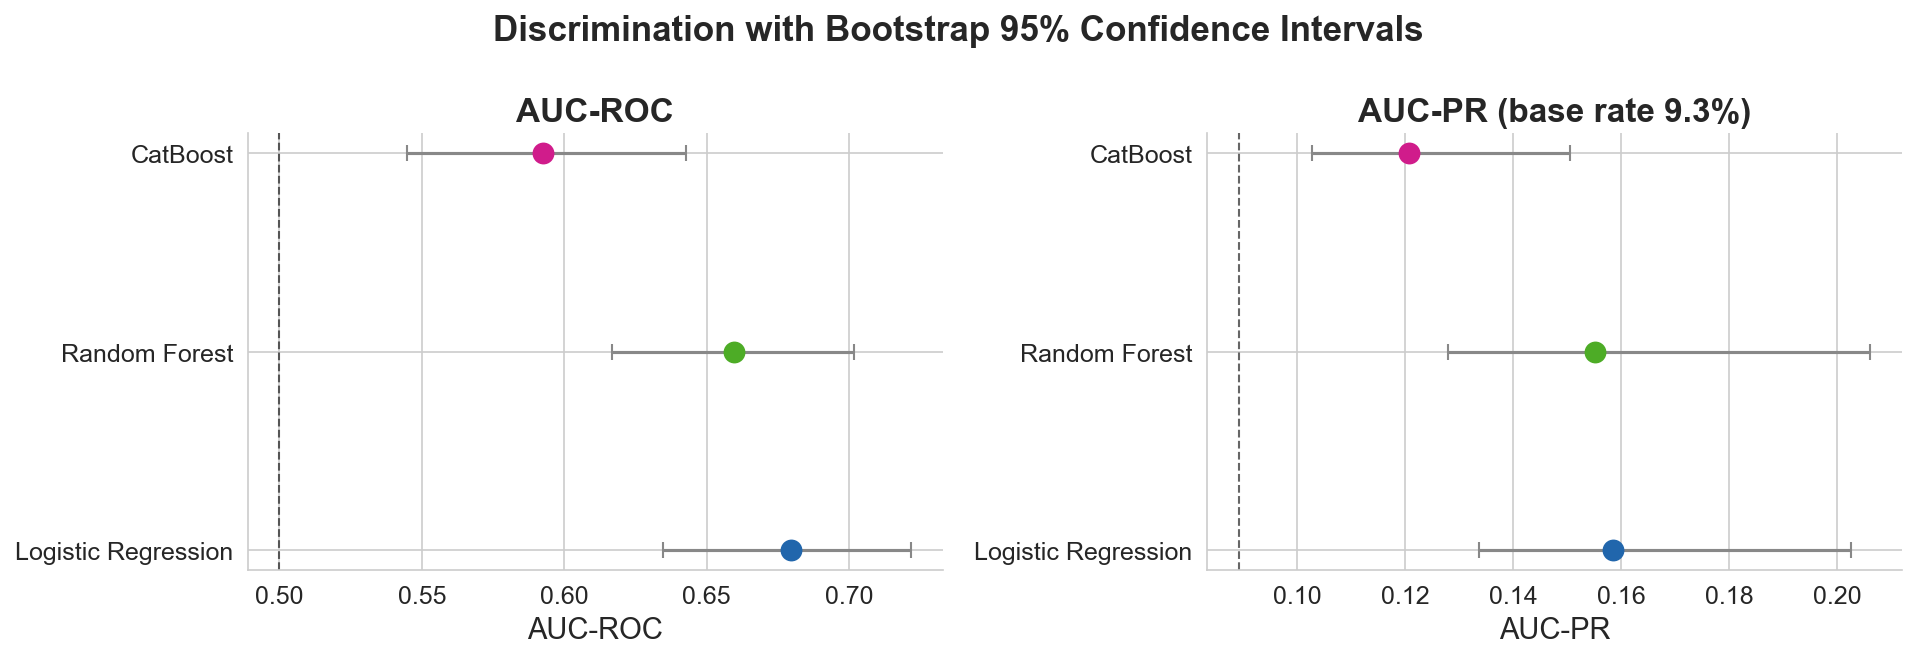

✓ Saved → figures/AdvStats_bootstrap_CIs.png


In [13]:
# ── C1: Bootstrap 95% CIs for AUC-ROC and AUC-PR ──────────────────────────────
def stratified_bootstrap_ci(y_true, y_prob, metric_fn, B=2000, seed=RNG_SEED):
    """Stratified (by class) bootstrap percentile CI for a probability metric."""
    y_true = np.asarray(y_true); y_prob = np.asarray(y_prob)
    idx_pos = np.where(y_true == 1)[0]; idx_neg = np.where(y_true == 0)[0]
    brng = np.random.default_rng(seed)
    stats_b = np.empty(B)
    for b in range(B):
        sp = brng.choice(idx_pos, size=len(idx_pos), replace=True)
        sn = brng.choice(idx_neg, size=len(idx_neg), replace=True)
        s = np.concatenate([sp, sn])
        stats_b[b] = metric_fn(y_true[s], y_prob[s])
    point = metric_fn(y_true, y_prob)
    lo, hi = np.percentile(stats_b, [2.5, 97.5])
    return point, lo, hi

ci_rows = []
for name, probs in MODELS.items():
    auc, auc_lo, auc_hi = stratified_bootstrap_ci(y_ml, probs, roc_auc_score)
    ap,  ap_lo,  ap_hi  = stratified_bootstrap_ci(y_ml, probs, average_precision_score)
    ci_rows.append({'Model': name, 'AUC-ROC': auc, 'ROC 2.5%': auc_lo, 'ROC 97.5%': auc_hi,
                    'AUC-PR': ap, 'PR 2.5%': ap_lo, 'PR 97.5%': ap_hi})
ci_df = pd.DataFrame(ci_rows).set_index('Model')
ci_df.to_csv('figures/AdvStats_bootstrap_CIs.csv')
print('Bootstrap 95% CIs (B=2,000, stratified):')
print(ci_df.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (metric, lo, hi, title) in zip(
        axes, [('AUC-ROC', 'ROC 2.5%', 'ROC 97.5%', 'AUC-ROC'),
               ('AUC-PR', 'PR 2.5%', 'PR 97.5%', 'AUC-PR (base rate 9.3%)')]):
    ypos = np.arange(len(ci_df)); pts = ci_df[metric].values
    err = np.vstack([pts - ci_df[lo].values, ci_df[hi].values - pts])
    ax.errorbar(pts, ypos, xerr=err, fmt='o', capsize=4, color='#444', ecolor='#888')
    for yp, p, m in zip(ypos, pts, ci_df.index):
        ax.scatter([p], [yp], color=MODEL_COLORS[m], s=90, zorder=3)
    ax.set_yticks(ypos); ax.set_yticklabels(ci_df.index)
    ax.set_xlabel(metric); ax.set_title(title, fontweight='bold')
    ax.axvline(0.5 if metric == 'AUC-ROC' else y_ml.mean(), color='k', ls='--', lw=1, alpha=0.6)
    for sp in ('top', 'right'):
        ax.spines[sp].set_visible(False)
plt.suptitle('Discrimination with Bootstrap 95% Confidence Intervals', fontweight='bold')
plt.tight_layout(); plt.savefig('figures/AdvStats_bootstrap_CIs.png'); plt.show()
print('✓ Saved → figures/AdvStats_bootstrap_CIs.png')

Calibration metrics (lower Brier/ECE = better; HL_p > 0.05 = adequate fit):


              Model Calibration  Brier    ECE  HL_chi2   HL_p    AUC
Logistic Regression         Raw 0.0803 0.0169  14.9208 0.0607 0.6795
Logistic Regression       Platt 0.0797 0.0101  12.1972 0.1426 0.6763
Logistic Regression    Isotonic 0.0802 0.0075  21.2063 0.0066 0.6537
      Random Forest         Raw 0.1672 0.2852 599.3267 0.0000 0.6594
      Random Forest       Platt 0.0794 0.0013  12.8655 0.1166 0.6539
      Random Forest    Isotonic 0.0799 0.0061   4.7284 0.7862 0.6414
           CatBoost         Raw 0.1349 0.1600 419.7282 0.0000 0.5927
           CatBoost       Platt 0.0808 0.0039   3.4842 0.9004 0.5829
           CatBoost    Isotonic 0.0812 0.0111  29.6324 0.0002 0.5599


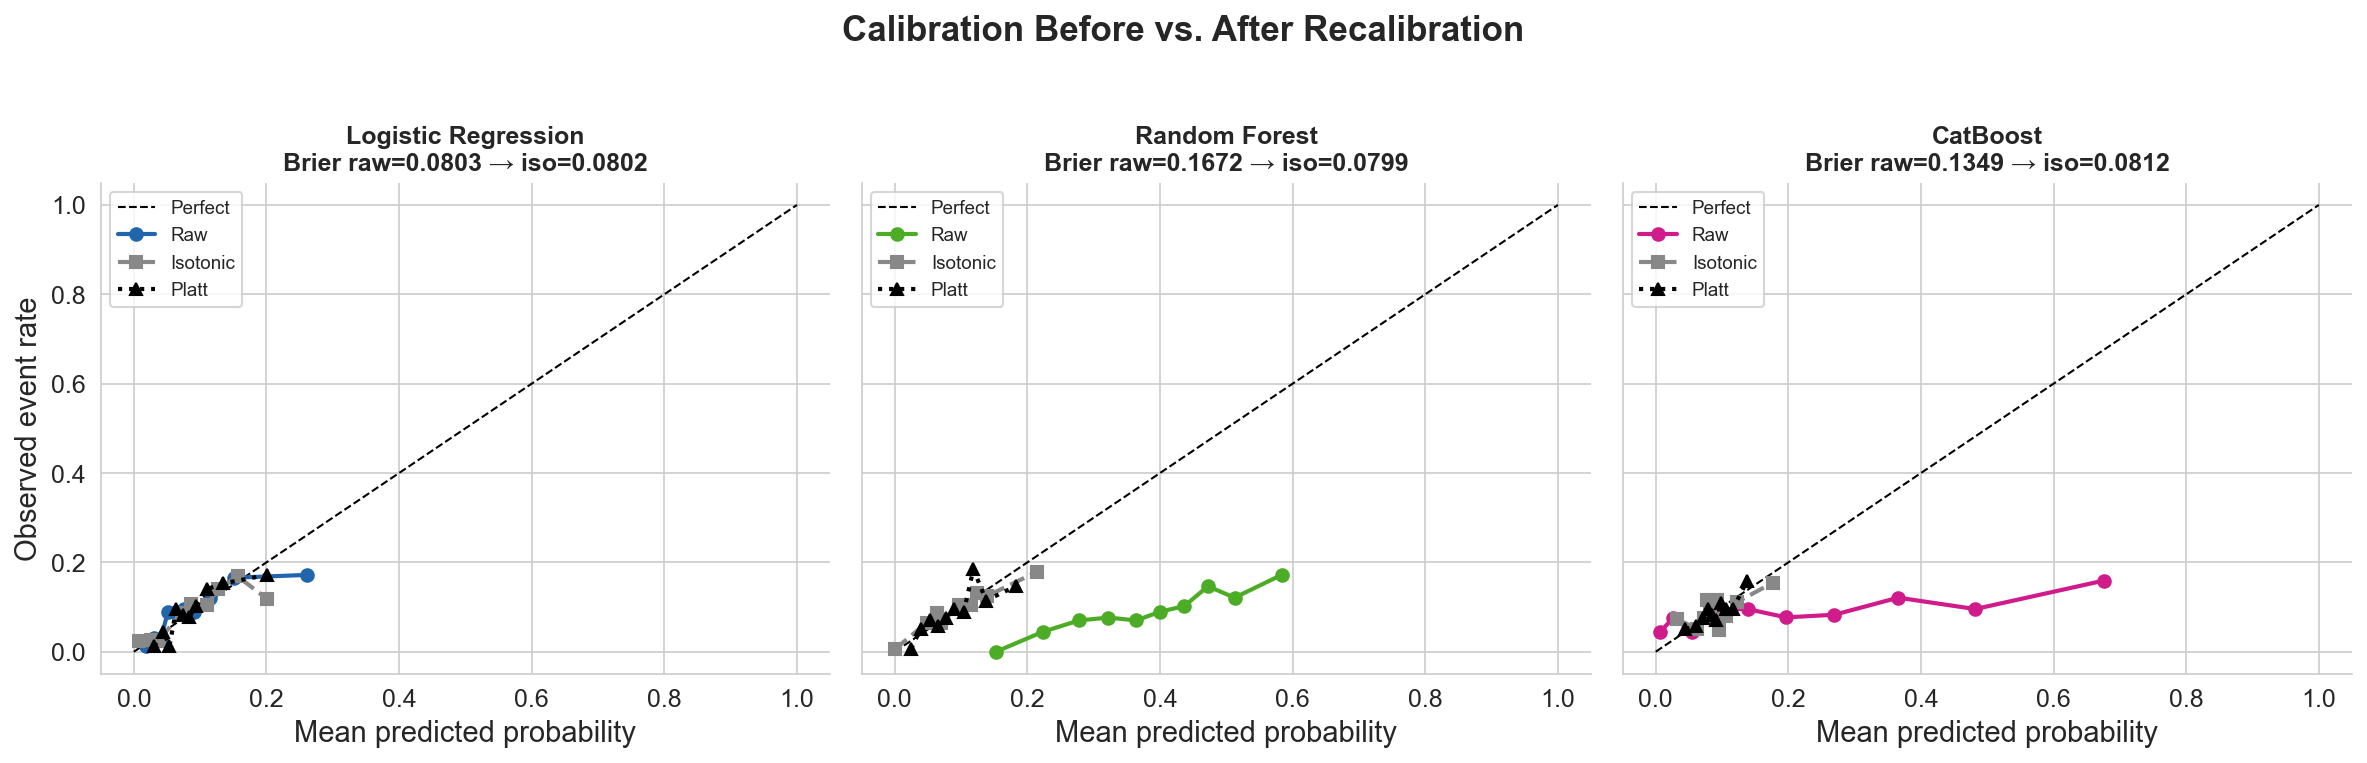

✓ Saved → figures/AdvStats_recalibration.png


In [14]:
# ── C2: Calibration metrics + Platt/isotonic recalibration ────────────────────
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.model_selection import KFold

def expected_calibration_error(y_true, y_prob, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1)
    idx = np.digitize(y_prob, bins[1:-1])
    ece = 0.0
    for b in range(n_bins):
        m = idx == b
        if m.sum() == 0:
            continue
        ece += (m.mean()) * abs(y_true[m].mean() - y_prob[m].mean())
    return ece

def hosmer_lemeshow(y_true, y_prob, g=10):
    order = np.argsort(y_prob)
    yt = np.asarray(y_true)[order]; yp = np.asarray(y_prob)[order]
    groups = np.array_split(np.arange(len(yp)), g)
    hl = 0.0
    for grp in groups:
        if len(grp) == 0:
            continue
        obs = yt[grp].sum(); exp = yp[grp].sum(); n = len(grp)
        if 0 < exp < n:
            hl += (obs - exp) ** 2 / (exp * (1 - exp / n))
    p = 1 - stats.chi2.cdf(hl, g - 2)
    return hl, p

def recalibrate(y_true, y_prob, method, n_splits=5, seed=RNG_SEED):
    y_true = np.asarray(y_true); y_prob = np.asarray(y_prob)
    out = np.zeros_like(y_prob, dtype=float)
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=seed)
    eps = 1e-6
    for tr, te in kf.split(y_prob):
        if method == 'platt':
            z_tr = np.log(np.clip(y_prob[tr], eps, 1 - eps) / (1 - np.clip(y_prob[tr], eps, 1 - eps)))
            z_te = np.log(np.clip(y_prob[te], eps, 1 - eps) / (1 - np.clip(y_prob[te], eps, 1 - eps)))
            lr = LogisticRegression().fit(z_tr.reshape(-1, 1), y_true[tr])
            out[te] = lr.predict_proba(z_te.reshape(-1, 1))[:, 1]
        else:
            ir = IsotonicRegression(out_of_bounds='clip').fit(y_prob[tr], y_true[tr])
            out[te] = ir.predict(y_prob[te])
    return out

cal_rows = []; recal_store = {}
for name, probs in MODELS.items():
    for label, p in [('Raw', probs), ('Platt', recalibrate(y_ml, probs, 'platt')),
                     ('Isotonic', recalibrate(y_ml, probs, 'isotonic'))]:
        hl, hl_p = hosmer_lemeshow(y_ml, p)
        cal_rows.append({'Model': name, 'Calibration': label,
                         'Brier': brier_score_loss(y_ml, p),
                         'ECE': expected_calibration_error(y_ml, p),
                         'HL_chi2': hl, 'HL_p': hl_p, 'AUC': roc_auc_score(y_ml, p)})
        recal_store[(name, label)] = p
cal_df = pd.DataFrame(cal_rows)
cal_df.to_csv('figures/AdvStats_calibration_metrics.csv', index=False)
print('Calibration metrics (lower Brier/ECE = better; HL_p > 0.05 = adequate fit):')
print(cal_df.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)
for ax, (name, probs) in zip(axes, MODELS.items()):
    ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Perfect')
    for label, style in [('Raw', dict(marker='o', ls='-', color=MODEL_COLORS[name])),
                         ('Isotonic', dict(marker='s', ls='--', color='#888')),
                         ('Platt', dict(marker='^', ls=':', color='#000'))]:
        p = recal_store[(name, label)]
        frac, mean_pred = calibration_curve(y_ml, p, n_bins=10, strategy='quantile')
        ax.plot(mean_pred, frac, lw=2, markersize=6, label=label, **style)
    b_raw = brier_score_loss(y_ml, recal_store[(name, 'Raw')])
    b_iso = brier_score_loss(y_ml, recal_store[(name, 'Isotonic')])
    ax.set_title(f'{name}\nBrier raw={b_raw:.4f} → iso={b_iso:.4f}', fontweight='bold', fontsize=12)
    ax.set_xlabel('Mean predicted probability'); ax.legend(fontsize=9)
    for sp in ('top', 'right'):
        ax.spines[sp].set_visible(False)
axes[0].set_ylabel('Observed event rate')
plt.suptitle('Calibration Before vs. After Recalibration', fontweight='bold', y=1.02)
plt.tight_layout(); plt.savefig('figures/AdvStats_recalibration.png'); plt.show()
print('✓ Saved → figures/AdvStats_recalibration.png')

Primary fairness model: Logistic Regression | global threshold (Youden J) = 0.076



Equity panel — Logistic Regression @ threshold 0.076:
                           N  Events  Event rate  Mean pred    AUC  AUC_lo  AUC_hi    TPR    FPR    FNR    PPV  Alert rate  Calib ratio
Male                   758.0    72.0       0.095      0.094  0.710   0.651   0.769  0.778  0.433  0.222  0.159       0.466        0.994
Female                 811.0    68.0       0.084      0.085  0.646   0.588   0.706  0.632  0.401  0.368  0.126       0.420        1.016
Public insurance       960.0    90.0       0.094      0.095  0.693   0.640   0.743  0.744  0.437  0.256  0.150       0.466        1.009
Private insurance      609.0    50.0       0.082      0.082  0.650   0.580   0.727  0.640  0.385  0.360  0.130       0.406        0.997
Age <=9                641.0    67.0       0.105      0.109  0.697   0.636   0.756  0.806  0.497  0.194  0.159       0.529        1.040
Age >=10               928.0    73.0       0.079      0.076  0.657   0.597   0.714  0.616  0.363  0.384  0.127       0.383       

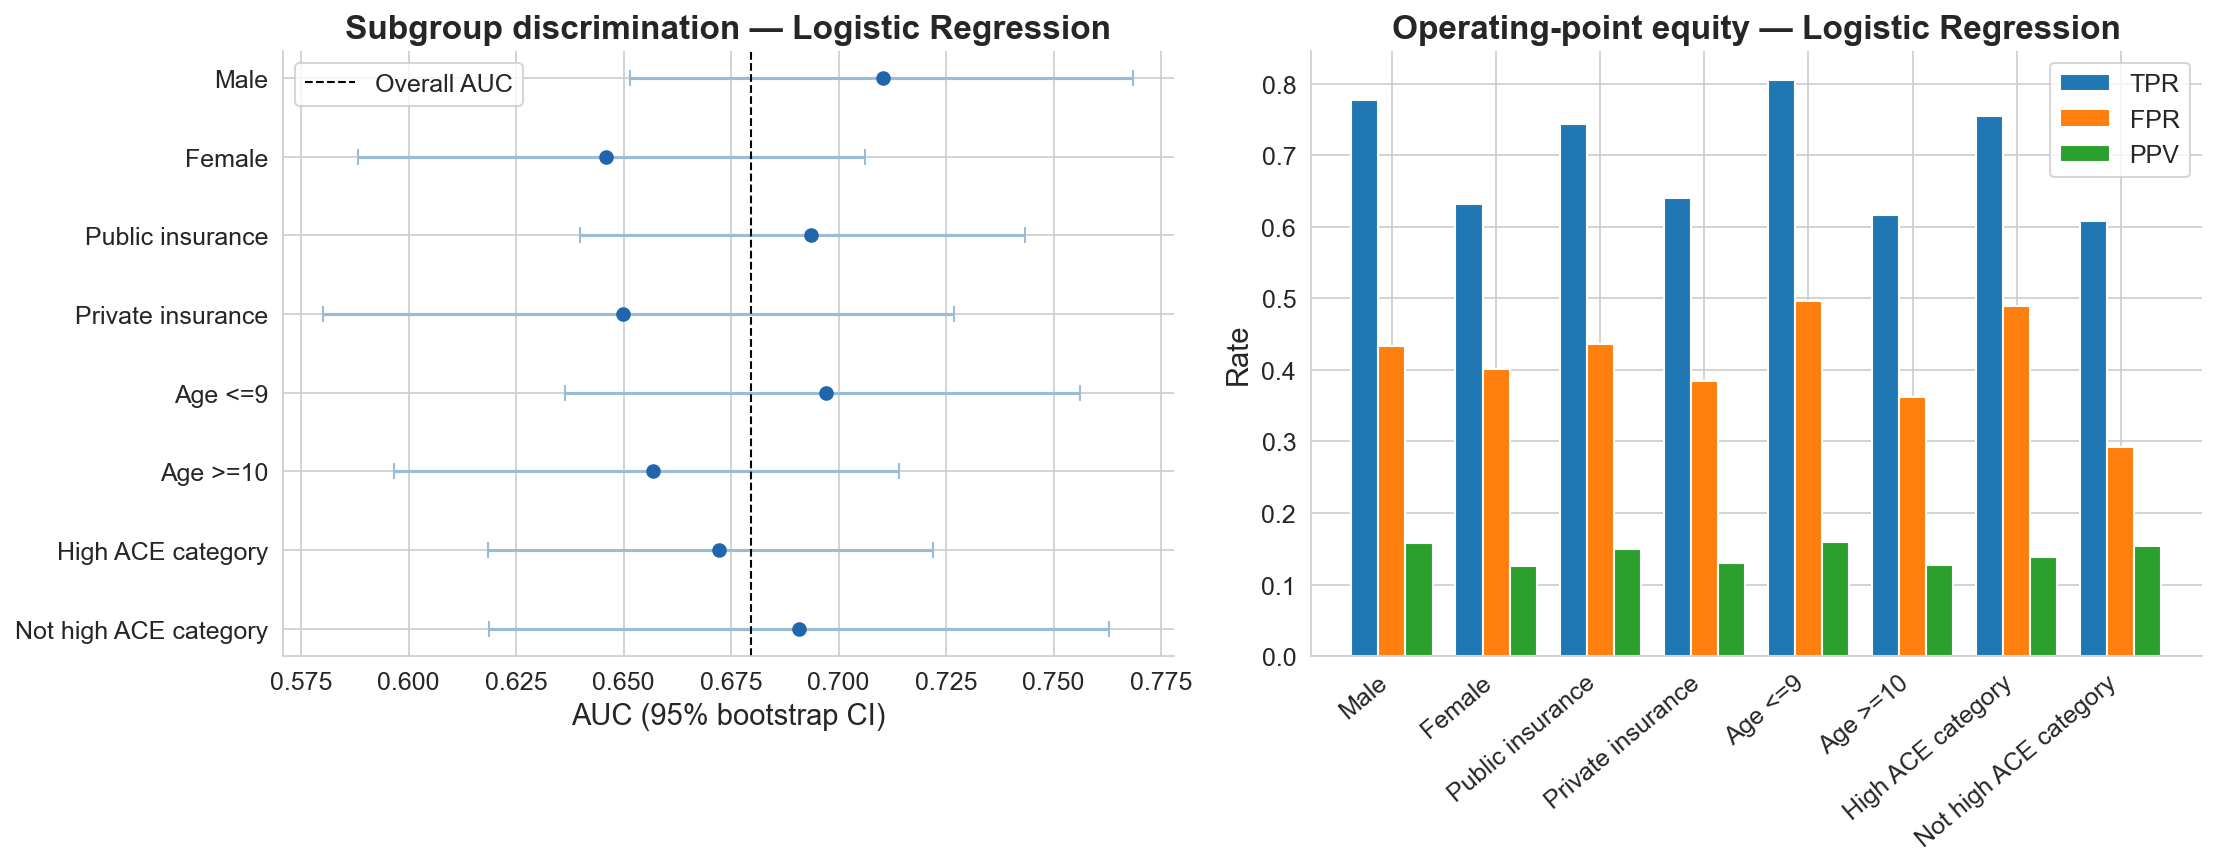

✓ Saved → figures/AdvStats_fairness.png


In [15]:
# ── C3: Fairness / equity metrics across protected subgroups ──────────────────
best_name = max(MODELS, key=lambda n: roc_auc_score(y_ml, MODELS[n]))
best_probs = MODELS[best_name]
fpr_g, tpr_g, thr_g = roc_curve(y_ml, best_probs)
thr_opt = thr_g[np.argmax(tpr_g - fpr_g)]   # Youden's J
print(f"Primary fairness model: {best_name} | global threshold (Youden J) = {thr_opt:.3f}")

mu = model_df_unscaled
_high_ace = mu['high_ace_expanded'].values
subgroups = {
    'Male': mu['gender_male'].values == 1,           'Female': mu['gender_male'].values == 0,
    'Public insurance': mu['insurance_public'].values == 1,
    'Private insurance': mu['insurance_public'].values == 0,
    'Age <=9': mu['age'].values <= 9,                'Age >=10': mu['age'].values >= 10,
    'High ACE category': _high_ace == 1,
    'Not high ACE category': _high_ace == 0,
}

def subgroup_panel(mask, probs, thr):
    yt = y_ml[mask]; pp = probs[mask]; pred = (pp >= thr).astype(int)
    out = {'N': int(mask.sum()), 'Events': int(yt.sum()),
           'Event rate': yt.mean(), 'Mean pred': pp.mean()}
    if yt.sum() >= 5 and (yt == 0).sum() >= 5:
        auc, lo, hi = stratified_bootstrap_ci(yt, pp, roc_auc_score, B=1000)
        out.update({'AUC': auc, 'AUC_lo': lo, 'AUC_hi': hi})
    else:
        out.update({'AUC': np.nan, 'AUC_lo': np.nan, 'AUC_hi': np.nan})
    tn, fp, fn, tp = confusion_matrix(yt, pred, labels=[0, 1]).ravel()
    out['TPR'] = tp / (tp + fn) if (tp + fn) else np.nan
    out['FPR'] = fp / (fp + tn) if (fp + tn) else np.nan
    out['FNR'] = fn / (fn + tp) if (fn + tp) else np.nan
    out['PPV'] = tp / (tp + fp) if (tp + fp) else np.nan
    out['Alert rate'] = pred.mean()
    out['Calib ratio'] = (pp.mean() / yt.mean()) if yt.mean() else np.nan
    return out

fair_df = pd.DataFrame({sg: subgroup_panel(m, best_probs, thr_opt)
                        for sg, m in subgroups.items()}).T
fair_df.to_csv('figures/AdvStats_fairness_subgroups.csv')
print(f"\nEquity panel — {best_name} @ threshold {thr_opt:.3f}:")
print(fair_df.round(3).to_string())

pairings = {'Sex (M vs F)': ('Male', 'Female'),
            'Insurance (Public vs Private)': ('Public insurance', 'Private insurance'),
            'Age (<=9 vs >=10)': ('Age <=9', 'Age >=10'),
            'ACE category (high vs not high)': ('High ACE category', 'Not high ACE category')}
disp_rows = []
for label, (a, b) in pairings.items():
    ra, rb = fair_df.loc[a], fair_df.loc[b]
    disp_rows.append({'Pairing': label, 'AUC gap': abs(ra['AUC'] - rb['AUC']),
        'Equalized-odds gap (max|dTPR|,|dFPR|)': max(abs(ra['TPR'] - rb['TPR']), abs(ra['FPR'] - rb['FPR'])),
        'Demographic-parity diff (|d alert|)': abs(ra['Alert rate'] - rb['Alert rate']),
        'FNR gap': abs(ra['FNR'] - rb['FNR'])})
disp_df = pd.DataFrame(disp_rows).set_index('Pairing')
disp_df.to_csv('figures/AdvStats_fairness_disparities.csv')
print('\nDisparity summary (0 = parity; larger = more inequitable):')
print(disp_df.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
order = list(subgroups.keys()); ypos = np.arange(len(order))[::-1]
auc_pt = fair_df.loc[order, 'AUC'].values.astype(float)
err = np.vstack([auc_pt - fair_df.loc[order, 'AUC_lo'].values.astype(float),
                 fair_df.loc[order, 'AUC_hi'].values.astype(float) - auc_pt])
axes[0].errorbar(auc_pt, ypos, xerr=err, fmt='o', capsize=4, color='#2166ac', ecolor='#9bbcd8')
axes[0].axvline(roc_auc_score(y_ml, best_probs), color='k', ls='--', lw=1, label='Overall AUC')
axes[0].set_yticks(ypos); axes[0].set_yticklabels(order)
axes[0].set_xlabel('AUC (95% bootstrap CI)')
axes[0].set_title(f'Subgroup discrimination — {best_name}', fontweight='bold'); axes[0].legend()
for sp in ('top', 'right'):
    axes[0].spines[sp].set_visible(False)
metrics_bar = ['TPR', 'FPR', 'PPV']; xb = np.arange(len(order)); w = 0.26
for k, met in enumerate(metrics_bar):
    axes[1].bar(xb + (k - 1) * w, fair_df.loc[order, met].values.astype(float), w, label=met)
axes[1].set_xticks(xb); axes[1].set_xticklabels(order, rotation=40, ha='right')
axes[1].set_ylabel('Rate'); axes[1].set_title(f'Operating-point equity — {best_name}', fontweight='bold')
axes[1].legend()
for sp in ('top', 'right'):
    axes[1].spines[sp].set_visible(False)
plt.tight_layout(); plt.savefig('figures/AdvStats_fairness.png'); plt.show()
print('✓ Saved → figures/AdvStats_fairness.png')

Logistic Regression    apparent=0.735  optimism=0.045  corrected=0.690


Random Forest          apparent=0.898  optimism=0.125  corrected=0.773


CatBoost               apparent=0.957  optimism=0.138  corrected=0.819



Nested-CV AUC — Random Forest: 0.655 | CatBoost: 0.666

Validation summary:
                     Apparent AUC  Optimism  Bootstrap-corrected AUC  10-fold OOF AUC  Nested-CV AUC
Model                                                                                               
Logistic Regression         0.735     0.045                    0.690            0.680            NaN
Random Forest               0.898     0.125                    0.773            0.659          0.655
CatBoost                    0.957     0.138                    0.819            0.593          0.666


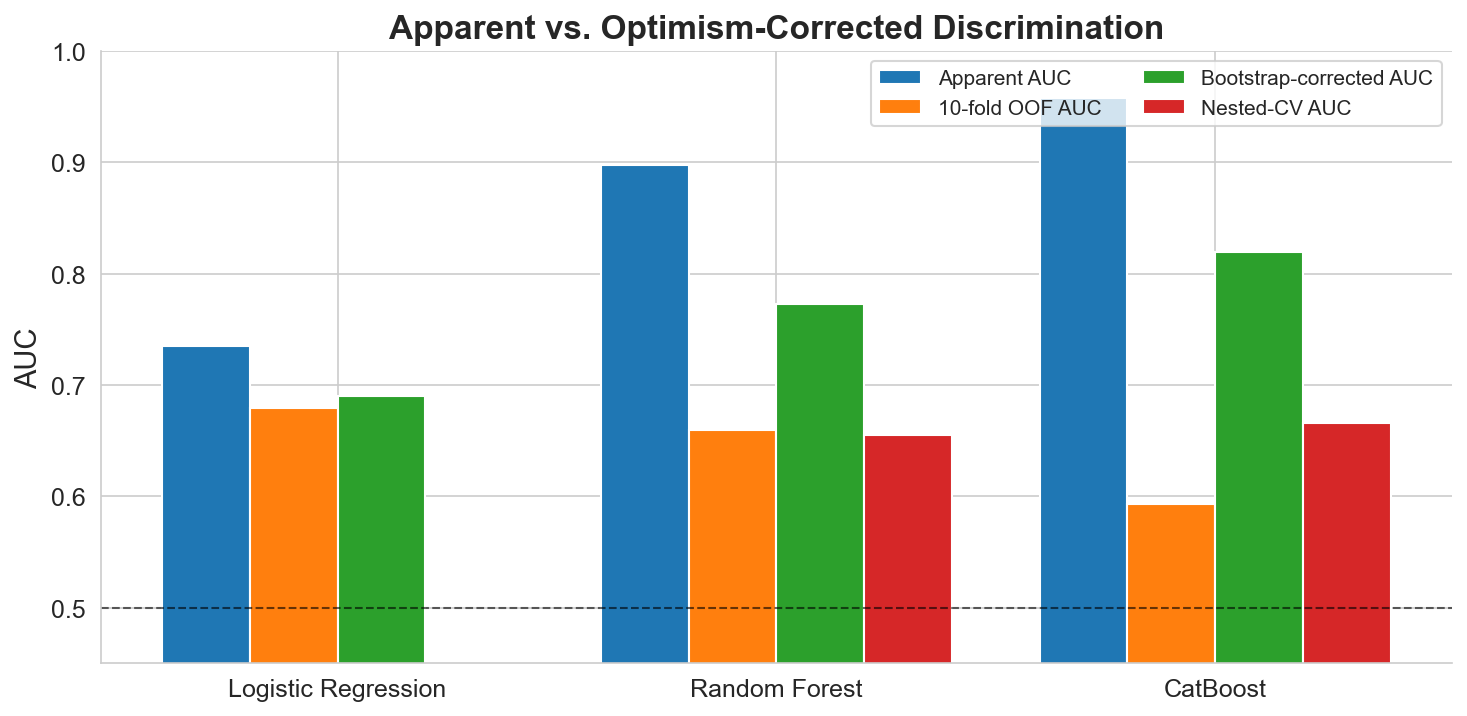

✓ Saved → figures/AdvStats_optimism_validation.png


In [16]:
# ── C4: Optimism-corrected validation (bootstrap + nested CV) ─────────────────
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, cross_val_score

def fit_lr(Xtr, ytr):
    return LogisticRegression(max_iter=2000, class_weight='balanced').fit(Xtr, ytr)
def fit_rf(Xtr, ytr):
    return RandomForestClassifier(n_estimators=400, max_depth=6, min_samples_leaf=10,
                                  class_weight='balanced', random_state=RNG_SEED, n_jobs=-1).fit(Xtr, ytr)
def fit_cb(Xtr, ytr):
    m = CatBoostClassifier(iterations=250, depth=4, learning_rate=0.05,
                           auto_class_weights='Balanced', random_seed=RNG_SEED, verbose=0)
    return m.fit(Xtr, ytr)

FITTERS = {'Logistic Regression': fit_lr, 'Random Forest': fit_rf, 'CatBoost': fit_cb}
B_OPT = {'Logistic Regression': 200, 'Random Forest': 150, 'CatBoost': 100}

def bootstrap_optimism(fitter, X, y, B, seed=RNG_SEED):
    """Harrell-Steyerberg optimism correction for AUC."""
    full = fitter(X, y)
    apparent = roc_auc_score(y, full.predict_proba(X)[:, 1])
    brng = np.random.default_rng(seed)
    n = len(y); opt = []
    for _ in range(B):
        idx = brng.integers(0, n, n)
        if y[idx].sum() < 2 or (y[idx] == 0).sum() < 2:
            continue
        mb = fitter(X[idx], y[idx])
        opt.append(roc_auc_score(y[idx], mb.predict_proba(X[idx])[:, 1]) -
                   roc_auc_score(y, mb.predict_proba(X)[:, 1]))
    optimism = float(np.mean(opt))
    return apparent, optimism, apparent - optimism

opt_rows = []
for name, fitter in FITTERS.items():
    app, optimism, corrected = bootstrap_optimism(fitter, X_ml, y_ml, B_OPT[name])
    opt_rows.append({'Model': name, 'Apparent AUC': app, 'Optimism': optimism,
                     'Bootstrap-corrected AUC': corrected,
                     '10-fold OOF AUC': roc_auc_score(y_ml, MODELS[name])})
    print(f"{name:<22} apparent={app:.3f}  optimism={optimism:.3f}  corrected={corrected:.3f}")

nested = {}
rf_grid = {'max_depth': [4, 6], 'min_samples_leaf': [10, 20]}
cb_grid = {'depth': [3, 4], 'learning_rate': [0.03, 0.05]}
nested['Random Forest'] = cross_val_score(
    GridSearchCV(RandomForestClassifier(n_estimators=300, class_weight='balanced',
                                         random_state=RNG_SEED, n_jobs=-1),
                 rf_grid, cv=3, scoring='roc_auc'), X_ml, y_ml, cv=5, scoring='roc_auc').mean()
nested['CatBoost'] = cross_val_score(
    GridSearchCV(CatBoostClassifier(iterations=200, auto_class_weights='Balanced',
                                    random_seed=RNG_SEED, verbose=0),
                 cb_grid, cv=3, scoring='roc_auc'), X_ml, y_ml, cv=5, scoring='roc_auc').mean()
print(f"\nNested-CV AUC — Random Forest: {nested['Random Forest']:.3f} | CatBoost: {nested['CatBoost']:.3f}")

opt_df = pd.DataFrame(opt_rows).set_index('Model')
opt_df['Nested-CV AUC'] = pd.Series(nested)
opt_df.to_csv('figures/AdvStats_optimism_validation.csv')
print('\nValidation summary:')
print(opt_df.round(3).to_string())

fig, ax = plt.subplots(figsize=(10, 5))
cols_plot = ['Apparent AUC', '10-fold OOF AUC', 'Bootstrap-corrected AUC', 'Nested-CV AUC']
xb = np.arange(len(opt_df)); w = 0.2
for k, col in enumerate(cols_plot):
    ax.bar(xb + (k - 1.5) * w, opt_df[col].values.astype(float), w, label=col)
ax.axhline(0.5, color='k', ls='--', lw=1, alpha=0.6)
ax.set_xticks(xb); ax.set_xticklabels(opt_df.index)
ax.set_ylabel('AUC'); ax.set_ylim(0.45, 1.0)
ax.set_title('Apparent vs. Optimism-Corrected Discrimination', fontweight='bold')
ax.legend(fontsize=10, ncol=2)
for sp in ('top', 'right'):
    ax.spines[sp].set_visible(False)
plt.tight_layout(); plt.savefig('figures/AdvStats_optimism_validation.png'); plt.show()
print('✓ Saved → figures/AdvStats_optimism_validation.png')